# LAB 05 - Sequence Models: RNN, LSTM and GRU

Bài làm mẫu cho sentiment classification trên sequence model.

Dataset: NLTK `movie_reviews` (2000 review phim, nhãn pos/neg, cùng nguồn với IMDb,
dùng làm bản thay thế chạy được trên CPU trong thời gian hợp lý, giống quy ước đã dùng ở LAB 04).
Chia stratified 70/15/15 (1400/300/300), seed 42.


In [1]:
import re
import io
import copy
import time
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

LABEL2ID = {"neg": 0, "pos": 1}
ID2LABEL = {0: "neg", 1: "pos"}
_TOKEN_RE = re.compile(r"[a-z']+")

results_rows = []


def log_result(experiment, setting, item, metric, value):
    results_rows.append(
        {"experiment": experiment, "setting": setting, "item": item, "metric": metric, "value": value}
    )


def tokenize(text):
    return _TOKEN_RE.findall(text.lower())

## Experiment 1 - Dataset inspection


In [2]:
def load_movie_reviews():
    import nltk

    try:
        from nltk.corpus import movie_reviews
        movie_reviews.fileids()
    except LookupError:
        nltk.download("movie_reviews")
        from nltk.corpus import movie_reviews

    texts, labels = [], []
    for fileid in movie_reviews.fileids():
        category = movie_reviews.categories(fileid)[0]
        texts.append(movie_reviews.raw(fileid))
        labels.append(LABEL2ID[category])
    return texts, labels


def stratified_split(texts, labels, val_size=0.15, test_size=0.15, seed=42):
    rng = random.Random(seed)
    texts = np.array(texts, dtype=object)
    labels = np.array(labels)
    train_idx, val_idx, test_idx = [], [], []
    for label in np.unique(labels):
        idx = np.where(labels == label)[0].tolist()
        rng.shuffle(idx)
        n = len(idx)
        n_val = int(round(n * val_size))
        n_test = int(round(n * test_size))
        val_idx.extend(idx[:n_val])
        test_idx.extend(idx[n_val:n_val + n_test])
        train_idx.extend(idx[n_val + n_test:])
    rng.shuffle(train_idx)
    rng.shuffle(val_idx)
    rng.shuffle(test_idx)

    def _subset(idx):
        return [texts[i] for i in idx], [int(labels[i]) for i in idx]

    return _subset(train_idx), _subset(val_idx), _subset(test_idx)


texts, labels = load_movie_reviews()
(train_texts, train_labels), (val_texts, val_labels), (test_texts, test_labels) = stratified_split(texts, labels)

n_pos = sum(labels)
n_neg = len(labels) - n_pos
doc_lengths = np.array([len(tokenize(t)) for t in texts])
n_dup = len(texts) - len(set(texts))
n_missing_text = sum(1 for t in texts if not t.strip())
n_missing_label = sum(1 for l in labels if l not in (0, 1))

print("so samples:", len(texts))
print("so classes:", len(set(labels)))
print("class distribution: pos=%d (%.1f%%) neg=%d (%.1f%%)" % (n_pos, 100 * n_pos / len(labels), n_neg, 100 * n_neg / len(labels)))
print("sequence length - min: %d, median: %.1f, mean: %.2f, max: %d" % (
    doc_lengths.min(), np.median(doc_lengths), doc_lengths.mean(), doc_lengths.max()))
print("duplicate documents:", n_dup)
print("missing text:", n_missing_text)
print("missing labels:", n_missing_label)
print("train/val/test size:", len(train_texts), len(val_texts), len(test_texts))

log_result("exp1", "full", "n_samples", "count", len(texts))
log_result("exp1", "full", "n_pos", "count", n_pos)
log_result("exp1", "full", "n_neg", "count", n_neg)
log_result("exp1", "full", "seq_len_min", "tokens", int(doc_lengths.min()))
log_result("exp1", "full", "seq_len_median", "tokens", float(np.median(doc_lengths)))
log_result("exp1", "full", "seq_len_mean", "tokens", float(doc_lengths.mean()))
log_result("exp1", "full", "seq_len_max", "tokens", int(doc_lengths.max()))
log_result("exp1", "full", "duplicates", "count", n_dup)
log_result("exp1", "full", "missing_text", "count", n_missing_text)
log_result("split", "train", "size", "count", len(train_texts))
log_result("split", "val", "size", "count", len(val_texts))
log_result("split", "test", "size", "count", len(test_texts))

so samples: 2000
so classes: 2
class distribution: pos=1000 (50.0%) neg=1000 (50.0%)
sequence length - min: 16, median: 612.0, mean: 651.98, max: 2390
duplicate documents: 0
missing text: 0
missing labels: 0
train/val/test size: 1400 300 300


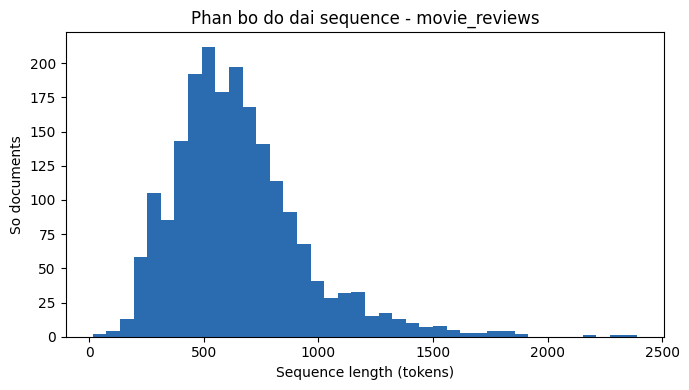

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(doc_lengths, bins=40, color="#2b6cb0")
ax.set_xlabel("Sequence length (tokens)")
ax.set_ylabel("So documents")
ax.set_title("Phan bo do dai sequence - movie_reviews")
plt.tight_layout()
plt.savefig("sequence_length_hist.png", dpi=120)
plt.show()

Trả lời: nếu phải chọn `max_length`, nên chọn dựa trên phân vị (percentile) của phân bố độ dài
sequence trên tập train (ví dụ median hoặc phân vị 80-90%), kết hợp quan sát training time và
F1 trên validation khi tăng max_length (xem Experiment 2/5), chứ không chọn một con số tuỳ ý vì
lý do "chạy nhanh". Nếu chọn max_length quá nhỏ so với phần lớn review (median ~612 token trong
dataset này), phần lớn nội dung sẽ bị cắt bỏ (xem % tokens retained ở Experiment 2).


## Tokenization và vocabulary


In [4]:
example = "I really like this movie"
print("text:", example)
print("tokens:", tokenize(example))

counter = Counter()
for t in train_texts:
    counter.update(tokenize(t))

VOCAB_SIZE_LIMIT = 10000
vocab = {"<PAD>": 0, "<UNK>": 1}
for w, c in counter.most_common(VOCAB_SIZE_LIMIT):
    vocab[w] = len(vocab)
print("vocabulary size (tren train, gioi han top %d tu):" % VOCAB_SIZE_LIMIT, len(vocab))
log_result("exp1", "full", "vocab_size", "count", len(vocab))


def encode(text, vocab, max_length):
    ids = [vocab.get(w, vocab["<UNK>"]) for w in tokenize(text)]
    real_len = min(len(ids), max_length)
    ids = ids[:max_length]
    if len(ids) < max_length:
        ids = ids + [vocab["<PAD>"]] * (max_length - len(ids))
    return ids, max(real_len, 1)


demo_ids, demo_len = encode(example, vocab, max_length=8)
print("token ids (padded to 8):", demo_ids, "real length:", demo_len)

text: I really like this movie
tokens: ['i', 'really', 'like', 'this', 'movie']


vocabulary size (tren train, gioi han top 10000 tu): 10002
token ids (padded to 8): [18, 98, 40, 15, 27, 0, 0, 0] real length: 5


`0 = <PAD>` không mang thông tin ngôn ngữ, chỉ dùng để các sequence trong cùng một batch có cùng
độ dài. `pack_padded_sequence` (dùng bên dưới) đảm bảo RNN/LSTM/GRU chỉ xử lý đúng `real_len`
token thực sự, không bị ảnh hưởng bởi các vị trí PAD phía sau. Truncation (cắt bớt token sau
`max_length`) khác với padding (thêm token giả): truncation làm mất thông tin thật sự, padding
chỉ là kỹ thuật để gom batch.


## Core implementation - Simple RNN cell

Xem file `rnn_cell.py`: `SimpleRNNCell` tự implement bằng numpy, thực hiện
`h_t = tanh(W_xh x_t + W_hh h_{t-1} + b_h)` và được đối chiếu với `torch.nn.RNNCell` trên cùng
một bộ trọng số (sai số tối đa ~1e-7, xem log khi chạy `python rnn_cell.py`).


In [5]:
import sys
sys.path.insert(0, ".")
from rnn_cell import SimpleRNNCell

cell = SimpleRNNCell(input_size=2, hidden_size=2, seed=0)
x_seq = np.array([[1.0, 0.0], [0.0, 1.0], [0.5, 0.5]])
h_seq = cell.forward_sequence(x_seq)
print("Vi du nho - input sequence:\n", x_seq)
print("Hidden states tu SimpleRNNCell:\n", np.round(h_seq, 6))

Vi du nho - input sequence:
 [[1.  0. ]
 [0.  1. ]
 [0.5 0.5]]
Hidden states tu SimpleRNNCell:
 [[ 0.191307 -0.571105]
 [-0.518425 -0.685936]
 [-0.601832 -0.747495]]


## Dataset / Dataloader và model dùng chung cho các experiment


In [6]:
class SeqDataset(Dataset):
    def __init__(self, texts, labels, vocab, max_length):
        self.data = [encode(t, vocab, max_length) for t in texts]
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        ids, length = self.data[idx]
        return torch.tensor(ids, dtype=torch.long), length, torch.tensor(self.labels[idx], dtype=torch.float32)


class SeqClassifier(nn.Module):
    """Embedding -> RNN/LSTM/GRU -> Linear, dung hidden state cuoi cung (tai vi tri token thuc,
    khong tinh PAD) de phan loai."""

    def __init__(self, vocab_size, emb_dim, hidden_size, cell_type="RNN", pad_idx=0, fc_dropout=0.4):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        cell_cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell_type]
        self.rnn = cell_cls(emb_dim, hidden_size, batch_first=True)
        self.cell_type = cell_type
        self.drop = nn.Dropout(fc_dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x, lengths):
        emb = self.embedding(x)
        packed = nn.utils.rnn.pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.rnn(packed)
        h_last = h[0] if self.cell_type == "LSTM" else h
        h_last = h_last[-1]
        logits = self.fc(self.drop(h_last)).squeeze(-1)
        return logits


def run_training(cell_type, max_length, vocab, epochs=10, hidden_size=64, emb_dim=100,
                  batch_size=32, lr=1e-3, weight_decay=1e-5, verbose=False):
    train_ds = SeqDataset(train_texts, train_labels, vocab, max_length)
    val_ds = SeqDataset(val_texts, val_labels, vocab, max_length)
    test_ds = SeqDataset(test_texts, test_labels, vocab, max_length)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size)
    test_loader = DataLoader(test_ds, batch_size=batch_size)

    model = SeqClassifier(len(vocab), emb_dim, hidden_size, cell_type)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()

    def _eval(loader, n):
        model.eval()
        preds, trues = [], []
        total_loss = 0.0
        with torch.no_grad():
            for x, lengths, y in loader:
                logits = model(x, lengths)
                total_loss += loss_fn(logits, y).item() * len(y)
                p = (torch.sigmoid(logits) > 0.5).long().numpy()
                preds.extend(p.tolist())
                trues.extend(y.long().numpy().tolist())
        avg_loss = total_loss / n
        acc = accuracy_score(trues, preds)
        prec, rec, f1, _ = precision_recall_fscore_support(trues, preds, average="binary", zero_division=0)
        return avg_loss, acc, prec, rec, f1, trues, preds

    history = []
    best_val_f1 = -1.0
    best_state = None
    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for x, lengths, y in train_loader:
            opt.zero_grad()
            logits = model(x, lengths)
            loss = loss_fn(logits, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            total_loss += loss.item() * len(y)
        train_loss = total_loss / len(train_ds)
        val_loss, val_acc, val_prec, val_rec, val_f1, _, _ = _eval(val_loader, len(val_ds))
        history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss, "val_f1": val_f1})
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())
        if verbose:
            print(f"[{cell_type} L={max_length}] epoch {epoch+1}: train_loss={train_loss:.4f} "
                  f"val_loss={val_loss:.4f} val_f1={val_f1:.4f}")
    train_time = time.time() - t0

    model.load_state_dict(best_state)
    test_loss, test_acc, test_prec, test_rec, test_f1, trues, preds = _eval(test_loader, len(test_ds))

    return {
        "model": model,
        "n_params": n_params,
        "train_time": train_time,
        "history": history,
        "test_acc": test_acc,
        "test_prec": test_prec,
        "test_rec": test_rec,
        "test_f1": test_f1,
        "trues": trues,
        "preds": preds,
        "vocab": vocab,
        "max_length": max_length,
        "cell_type": cell_type,
    }

## Experiment 2 - Padding và truncation


In [7]:
MAX_LENGTHS = [50, 100, 200]
exp2_rows = []
exp2_results = {}
for ml in MAX_LENGTHS:
    pct_retained = float(np.mean(np.minimum(doc_lengths, ml) / doc_lengths))
    res = run_training("RNN", ml, vocab, epochs=6, verbose=True)
    exp2_results[ml] = res
    row = {
        "max_length": ml,
        "pct_tokens_retained": round(100 * pct_retained, 2),
        "training_time_s": round(res["train_time"], 2),
        "accuracy": round(res["test_acc"], 4),
        "f1": round(res["test_f1"], 4),
    }
    exp2_rows.append(row)
    log_result("exp2", f"rnn_L{ml}", "pct_tokens_retained", "percentage", round(100 * pct_retained, 2))
    log_result("exp2", f"rnn_L{ml}", "training_time", "seconds", round(res["train_time"], 2))
    log_result("exp2", f"rnn_L{ml}", "accuracy", "score", round(res["test_acc"], 4))
    log_result("exp2", f"rnn_L{ml}", "f1", "score", round(res["test_f1"], 4))

exp2_df = pd.DataFrame(exp2_rows)
print(exp2_df.to_string(index=False))

[RNN L=50] epoch 1: train_loss=0.7088 val_loss=0.7003 val_f1=0.5627


[RNN L=50] epoch 2: train_loss=0.6794 val_loss=0.7003 val_f1=0.5566


[RNN L=50] epoch 3: train_loss=0.6539 val_loss=0.7048 val_f1=0.5545


[RNN L=50] epoch 4: train_loss=0.6354 val_loss=0.7067 val_f1=0.5621


[RNN L=50] epoch 5: train_loss=0.5926 val_loss=0.7182 val_f1=0.5868


...

[RNN L=200] epoch 2: train_loss=0.6696 val_loss=0.7089 val_f1=0.4795


[RNN L=200] epoch 3: train_loss=0.6451 val_loss=0.7241 val_f1=0.4883


[RNN L=200] epoch 4: train_loss=0.6110 val_loss=0.7423 val_f1=0.4949


[RNN L=200] epoch 5: train_loss=0.5603 val_loss=0.7893 val_f1=0.4897


[RNN L=200] epoch 6: train_loss=0.5012 val_loss=0.8447 val_f1=0.4765
 max_length  pct_tokens_retained  training_time_s  accuracy     f1
         50                 9.38             9.15    0.5233 0.5342
        100                18.68            21.64    0.4933 0.5309
        200                36.98           116.35    0.5233 0.5460


Trả lời: tăng `max_length` không luôn cải thiện performance - khi `max_length` quá lớn so với
độ dài trung bình, số bước recurrent phải thực hiện tăng lên, làm vanishing gradient rõ rệt hơn
và training time tăng mạnh, trong khi phần token mới thêm vào có thể là nội dung ít liên quan
trực tiếp đến sentiment (mô tả chi tiết, diễn biến). Nếu `max_length` quá nhỏ, các từ/cụm từ
quyết định sentiment nằm ở cuối review (ví dụ câu kết luận) có thể bị cắt bỏ hoàn toàn (xem %
tokens retained ở bảng trên, rất thấp với max_length=50 do review trung bình dài ~650 token).


## Experiment 3 - Baseline TF-IDF + Logistic Regression vs Embedding + RNN


In [8]:
MAIN_MAX_LENGTH = 150

t0 = time.time()
tfidf = TfidfVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None)
X_train_tfidf = tfidf.fit_transform(train_texts)
X_val_tfidf = tfidf.transform(val_texts)
X_test_tfidf = tfidf.transform(test_texts)
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_tfidf, train_labels)
tfidf_train_time = time.time() - t0

test_pred_tfidf = lr.predict(X_test_tfidf)
tfidf_acc = accuracy_score(test_labels, test_pred_tfidf)
tfidf_prec, tfidf_rec, tfidf_f1, _ = precision_recall_fscore_support(
    test_labels, test_pred_tfidf, average="binary", zero_division=0)

rnn_main = run_training("RNN", MAIN_MAX_LENGTH, vocab, epochs=10, verbose=True)

exp3_table = pd.DataFrame([
    {"model": "Logistic Regression", "representation": "TF-IDF", "accuracy": round(tfidf_acc, 4),
     "precision": round(tfidf_prec, 4), "recall": round(tfidf_rec, 4), "f1": round(tfidf_f1, 4),
     "training_time_s": round(tfidf_train_time, 3)},
    {"model": "RNN", "representation": "Embedding", "accuracy": round(rnn_main["test_acc"], 4),
     "precision": round(rnn_main["test_prec"], 4), "recall": round(rnn_main["test_rec"], 4),
     "f1": round(rnn_main["test_f1"], 4), "training_time_s": round(rnn_main["train_time"], 2)},
])
print(exp3_table.to_string(index=False))

log_result("exp3", "tfidf_lr", "vocab_size", "count", len(tfidf.vocabulary_))
log_result("exp3", "tfidf_lr", "training_time", "seconds", round(tfidf_train_time, 4))
log_result("exp3", "tfidf_lr", "accuracy", "score", round(tfidf_acc, 4))
log_result("exp3", "tfidf_lr", "precision", "score", round(tfidf_prec, 4))
log_result("exp3", "tfidf_lr", "recall", "score", round(tfidf_rec, 4))
log_result("exp3", "tfidf_lr", "f1", "score", round(tfidf_f1, 4))
log_result("exp3", "rnn_embedding", "training_time", "seconds", round(rnn_main["train_time"], 2))
log_result("exp3", "rnn_embedding", "accuracy", "score", round(rnn_main["test_acc"], 4))
log_result("exp3", "rnn_embedding", "precision", "score", round(rnn_main["test_prec"], 4))
log_result("exp3", "rnn_embedding", "recall", "score", round(rnn_main["test_rec"], 4))
log_result("exp3", "rnn_embedding", "f1", "score", round(rnn_main["test_f1"], 4))

[RNN L=150] epoch 1: train_loss=0.7082 val_loss=0.7181 val_f1=0.4147


[RNN L=150] epoch 2: train_loss=0.6767 val_loss=0.7255 val_f1=0.4365


[RNN L=150] epoch 3: train_loss=0.6528 val_loss=0.7362 val_f1=0.4808


[RNN L=150] epoch 4: train_loss=0.6267 val_loss=0.7621 val_f1=0.4870


[RNN L=150] epoch 5: train_loss=0.5889 val_loss=0.7967 val_f1=0.4406


[RNN L=150] epoch 6: train_loss=0.5315 val_loss=0.8340 val_f1=0.4310


[RNN L=150] epoch 7: train_loss=0.4493 val_loss=0.8956 val_f1=0.4467


[RNN L=150] epoch 8: train_loss=0.3568 val_loss=1.0003 val_f1=0.4214


[RNN L=150] epoch 9: train_loss=0.2591 val_loss=1.1663 val_f1=0.4834


[RNN L=150] epoch 10: train_loss=0.1716 val_loss=1.3279 val_f1=0.5000
              model representation  accuracy  precision  recall     f1  training_time_s
Logistic Regression         TF-IDF    0.8133     0.8052  0.8267 0.8158            1.042
                RNN      Embedding    0.5467     0.5427  0.5933 0.5669           75.670


Câu hỏi: RNN có thực sự sử dụng thông tin sequence mà TF-IDF không sử dụng hay không?

Bằng chứng từ Experiment 4 và Experiment 6 (bên dưới): cùng một bộ từ (bag-of-words) nhưng sắp
xếp khác nhau sẽ cho TF-IDF cùng một vector (xem Bài 3 trong `calculations.md`), trong khi RNN
cho kết quả khác nhau tuỳ vị trí của từ khoá sentiment trong câu (Experiment 6). Đây là bằng
chứng trực tiếp rằng RNN khai thác thứ tự token, còn TF-IDF thì không, dù cả hai có thể đạt
accuracy khác nhau trên tập test ở quy mô dataset này.


## LSTM và GRU - Experiment 4: RNN vs LSTM vs GRU


In [9]:
exp4_results = {}
for cell_type in ["RNN", "LSTM", "GRU"]:
    if cell_type == "RNN":
        res = rnn_main
    else:
        res = run_training(cell_type, MAIN_MAX_LENGTH, vocab, epochs=10, verbose=True)
    exp4_results[cell_type] = res

exp4_rows = []
for cell_type, res in exp4_results.items():
    row = {
        "model": cell_type,
        "parameters": res["n_params"],
        "training_time_s": round(res["train_time"], 2),
        "accuracy": round(res["test_acc"], 4),
        "precision": round(res["test_prec"], 4),
        "recall": round(res["test_rec"], 4),
        "f1": round(res["test_f1"], 4),
    }
    exp4_rows.append(row)
    log_result("exp4", cell_type.lower(), "parameters", "count", res["n_params"])
    log_result("exp4", cell_type.lower(), "training_time", "seconds", round(res["train_time"], 2))
    log_result("exp4", cell_type.lower(), "accuracy", "score", round(res["test_acc"], 4))
    log_result("exp4", cell_type.lower(), "precision", "score", round(res["test_prec"], 4))
    log_result("exp4", cell_type.lower(), "recall", "score", round(res["test_rec"], 4))
    log_result("exp4", cell_type.lower(), "f1", "score", round(res["test_f1"], 4))

exp4_df = pd.DataFrame(exp4_rows)
print(exp4_df.to_string(index=False))

best_cell_type = exp4_df.sort_values("f1", ascending=False).iloc[0]["model"]
print("\nModel co F1 cao nhat tren test set:", best_cell_type)

[LSTM L=150] epoch 1: train_loss=0.6957 val_loss=0.6964 val_f1=0.4594


[LSTM L=150] epoch 2: train_loss=0.6788 val_loss=0.7005 val_f1=0.5161


[LSTM L=150] epoch 3: train_loss=0.6614 val_loss=0.7082 val_f1=0.5220


[LSTM L=150] epoch 4: train_loss=0.6231 val_loss=0.7363 val_f1=0.4380


[LSTM L=150] epoch 5: train_loss=0.5529 val_loss=0.7771 val_f1=0.5294


...

[GRU L=150] epoch 6: train_loss=0.5018 val_loss=0.7786 val_f1=0.4945


[GRU L=150] epoch 7: train_loss=0.4167 val_loss=0.8843 val_f1=0.5679


[GRU L=150] epoch 8: train_loss=0.3016 val_loss=0.9550 val_f1=0.5705


[GRU L=150] epoch 9: train_loss=0.1946 val_loss=1.1387 val_f1=0.6038


[GRU L=150] epoch 10: train_loss=0.1052 val_loss=1.3743 val_f1=0.5860
model  parameters  training_time_s  accuracy  precision  recall     f1
  RNN     1010889            75.67    0.5467     0.5427  0.5933 0.5669
 LSTM     1042761            38.32    0.5067     0.5059  0.5733 0.5375
  GRU     1032137            33.93    0.5533     0.5455  0.6400 0.5890

Model co F1 cao nhat tren test set: GRU


Câu hỏi: kết quả thực nghiệm có phù hợp với prediction ban đầu không? Xem lại `prediction.md`.
LSTM/GRU có thêm gate và cell state (với LSTM) giúp kiểm soát information flow tốt hơn RNN thuần
về mặt cơ chế (Bài tập tính toán LSTM gates, mục vanishing gradient trong `calculations.md`),
nhưng với dataset nhỏ (1400 sample train) và embedding khởi tạo ngẫu nhiên (không dùng pretrained
embedding), chênh lệch về accuracy/F1 tổng thể trên test set có thể không lớn, hoặc không nhất
quán giữa các lần chạy - đừng kết luận chỉ dựa vào accuracy, cần đối chiếu với parameters và
training time (model phức tạp hơn không tự động tốt hơn trên mọi dataset - xem Prediction 5).


## Experiment 5 - Sequence length (kiến trúc cố định = model tốt nhất ở Experiment 4)


[GRU L=50] epoch 1: train_loss=0.7003 val_loss=0.6978 val_f1=0.5247


[GRU L=50] epoch 2: train_loss=0.6750 val_loss=0.6996 val_f1=0.5237


[GRU L=50] epoch 3: train_loss=0.6541 val_loss=0.7072 val_f1=0.5329


[GRU L=50] epoch 4: train_loss=0.6283 val_loss=0.7168 val_f1=0.5212


[GRU L=50] epoch 5: train_loss=0.5847 val_loss=0.7385 val_f1=0.4741


...

[GRU L=200] epoch 5: train_loss=0.5789 val_loss=0.7498 val_f1=0.4676


[GRU L=200] epoch 6: train_loss=0.5104 val_loss=0.7759 val_f1=0.5203


[GRU L=200] epoch 7: train_loss=0.4169 val_loss=0.8466 val_f1=0.4706


[GRU L=200] epoch 8: train_loss=0.2845 val_loss=0.9293 val_f1=0.5282


 max_length  pct_tokens_retained  training_time_s  val_loss_last_epoch  test_f1
         50                 9.38             8.91               1.0010   0.4730
        100                18.68            17.59               1.0636   0.4868
        200                36.98           153.11               0.9293   0.5294


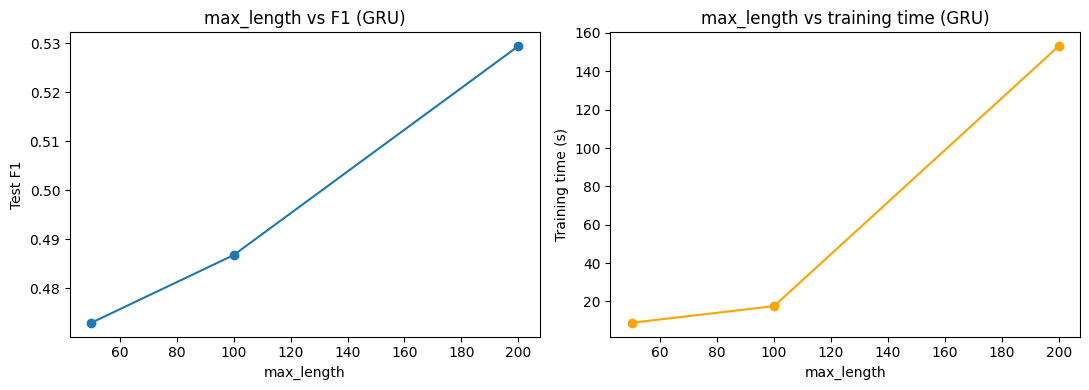

In [10]:
exp5_rows = []
exp5_results = {}
for ml in MAX_LENGTHS:
    if ml == MAIN_MAX_LENGTH:
        res = exp4_results[best_cell_type]
    else:
        res = run_training(best_cell_type, ml, vocab, epochs=8, verbose=True)
    exp5_results[ml] = res
    pct_retained = float(np.mean(np.minimum(doc_lengths, ml) / doc_lengths))
    val_loss_last = res["history"][-1]["val_loss"]
    row = {
        "max_length": ml,
        "pct_tokens_retained": round(100 * pct_retained, 2),
        "training_time_s": round(res["train_time"], 2),
        "val_loss_last_epoch": round(val_loss_last, 4),
        "test_f1": round(res["test_f1"], 4),
    }
    exp5_rows.append(row)
    log_result("exp5", f"{best_cell_type.lower()}_L{ml}", "pct_tokens_retained", "percentage", round(100 * pct_retained, 2))
    log_result("exp5", f"{best_cell_type.lower()}_L{ml}", "training_time", "seconds", round(res["train_time"], 2))
    log_result("exp5", f"{best_cell_type.lower()}_L{ml}", "val_loss_last_epoch", "loss", round(val_loss_last, 4))
    log_result("exp5", f"{best_cell_type.lower()}_L{ml}", "test_f1", "score", round(res["test_f1"], 4))

exp5_df = pd.DataFrame(exp5_rows)
print(exp5_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(exp5_df["max_length"], exp5_df["test_f1"], marker="o")
axes[0].set_xlabel("max_length")
axes[0].set_ylabel("Test F1")
axes[0].set_title(f"max_length vs F1 ({best_cell_type})")
axes[1].plot(exp5_df["max_length"], exp5_df["training_time_s"], marker="o", color="orange")
axes[1].set_xlabel("max_length")
axes[1].set_ylabel("Training time (s)")
axes[1].set_title(f"max_length vs training time ({best_cell_type})")
plt.tight_layout()
plt.savefig("sequence_length_tradeoff.png", dpi=120)
plt.show()

Trả lời: có tồn tại trade-off giữa context và computational cost. Tăng max_length giữ lại nhiều
context hơn (pct_tokens_retained tăng) nhưng làm training time tăng (nhiều bước recurrent hơn
cho mỗi sample) và không đảm bảo F1 tăng tương ứng, đặc biệt khi phần context thêm vào không
liên quan trực tiếp đến sentiment hoặc khi sequence dài hơn làm vanishing gradient rõ rệt hơn.


## Experiment 6 - Long-range dependency


In [11]:
FILLER = ("the film was shot in several locations and the crew spent many weeks "
          "working on lighting costumes and sound design before release ")

SENT_POS = "ultimately excellent"
SENT_NEG = "ultimately terrible"


def make_long_range_example(sentiment_phrase, position, n_filler_repeats=6):
    filler_block = (FILLER * n_filler_repeats).strip()
    filler_tokens = filler_block.split()
    if position == "beginning":
        text = sentiment_phrase + " " + " ".join(filler_tokens)
    elif position == "middle":
        half = len(filler_tokens) // 2
        text = " ".join(filler_tokens[:half]) + " " + sentiment_phrase + " " + " ".join(filler_tokens[half:])
    elif position == "end":
        text = " ".join(filler_tokens) + " " + sentiment_phrase
    else:
        raise ValueError(position)
    return text


best_model = exp4_results[best_cell_type]["model"]
best_vocab = vocab


def predict_proba(model, text, max_length):
    ids, length = encode(text, best_vocab, max_length)
    x = torch.tensor([ids], dtype=torch.long)
    lengths = torch.tensor([length])
    model.eval()
    with torch.no_grad():
        logit = model(x, lengths)
        return torch.sigmoid(logit).item()


exp6_rows = []
for sentiment_phrase, label in [(SENT_POS, "pos"), (SENT_NEG, "neg")]:
    for position in ["beginning", "middle", "end"]:
        text = make_long_range_example(sentiment_phrase, position)
        p = predict_proba(best_model, text, MAIN_MAX_LENGTH)
        exp6_rows.append({
            "sentiment_phrase": sentiment_phrase, "true_label": label,
            "position": position, "P_positive": round(p, 4),
        })
        log_result("exp6", f"{label}_{position}", "P_positive", "probability", round(p, 4))

exp6_df = pd.DataFrame(exp6_rows)
print(exp6_df.to_string(index=False))

    sentiment_phrase true_label  position  P_positive
ultimately excellent        pos beginning      0.8269
ultimately excellent        pos    middle      0.8301
ultimately excellent        pos       end      0.9436
 ultimately terrible        neg beginning      0.8269
 ultimately terrible        neg    middle      0.8238
 ultimately terrible        neg       end      0.8601


Quan sát: đây là một thí nghiệm nhỏ (empirical observation) trên một cặp câu tổng hợp, không
phải chứng minh đầy đủ vanishing gradient về mặt lý thuyết (theoretical explanation, xem mục
"Vanishing gradient" trong `calculations.md`). Nếu P_positive khi sentiment phrase nằm ở "end"
gần với giá trị mong đợi (gần 1 cho "excellent", gần 0 cho "terrible") hơn so với khi nó nằm ở
"beginning", đây là dấu hiệu thực nghiệm cho thấy thông tin gần vị trí đọc cuối cùng (gần h_T)
ảnh hưởng mạnh hơn tới prediction - phù hợp với cơ chế h_t = f(x_t, h_{t-1}), trong đó thông tin
từ các bước đầu phải "sống sót" qua nhiều phép nhân Jacobian hơn để còn ảnh hưởng tới h_T.


## Evaluation


Model danh gia chi tiet: GRU max_length = 150
parameters: 1032137
training_time (s): 33.93
epochs: 10
vocab_size: 10002
accuracy=0.5533 precision=0.5455 recall=0.6400 f1=0.5890
confusion matrix [[TN, FP], [FN, TP]]:
 [[70 80]
 [54 96]]


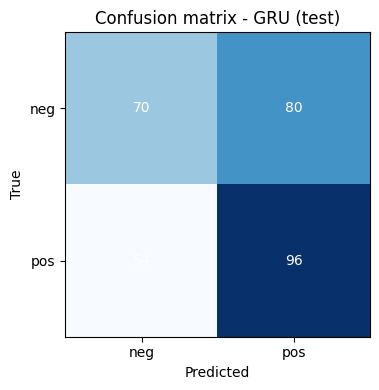

In [12]:
best_res = exp4_results[best_cell_type]
cm = confusion_matrix(best_res["trues"], best_res["preds"])
print("Model danh gia chi tiet:", best_cell_type, "max_length =", MAIN_MAX_LENGTH)
print("parameters:", best_res["n_params"])
print("training_time (s):", round(best_res["train_time"], 2))
print("epochs:", len(best_res["history"]))
print("vocab_size:", len(vocab))
print("accuracy=%.4f precision=%.4f recall=%.4f f1=%.4f" % (
    best_res["test_acc"], best_res["test_prec"], best_res["test_rec"], best_res["test_f1"]))
print("confusion matrix [[TN, FP], [FN, TP]]:\n", cm)

tn, fp, fn, tp = cm.ravel()
log_result("eval", f"{best_cell_type.lower()}_test", "TP", "count", int(tp))
log_result("eval", f"{best_cell_type.lower()}_test", "FP", "count", int(fp))
log_result("eval", f"{best_cell_type.lower()}_test", "FN", "count", int(fn))
log_result("eval", f"{best_cell_type.lower()}_test", "TN", "count", int(tn))
log_result("eval", f"{best_cell_type.lower()}_test", "parameters", "count", best_res["n_params"])
log_result("eval", f"{best_cell_type.lower()}_test", "training_time", "seconds", round(best_res["train_time"], 2))
log_result("eval", f"{best_cell_type.lower()}_test", "epochs", "count", len(best_res["history"]))
log_result("eval", f"{best_cell_type.lower()}_test", "vocab_size", "count", len(vocab))
log_result("eval", f"{best_cell_type.lower()}_test", "max_length", "tokens", MAIN_MAX_LENGTH)

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["neg", "pos"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["neg", "pos"])
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Confusion matrix - {best_cell_type} (test)")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=120)
plt.show()

## Learning curves


 epoch  train_loss  val_loss   val_f1
     1    0.693334  0.701191 0.455882
     2    0.673364  0.705874 0.500000
     3    0.652652  0.710357 0.549383
     4    0.618595  0.722373 0.500000
     5    0.567001  0.753816 0.504792
     6    0.501776  0.778590 0.494465
     7    0.416681  0.884339 0.567901
     8    0.301569  0.955026 0.570492
     9    0.194561  1.138750 0.603774
    10    0.105225  1.374318 0.585987


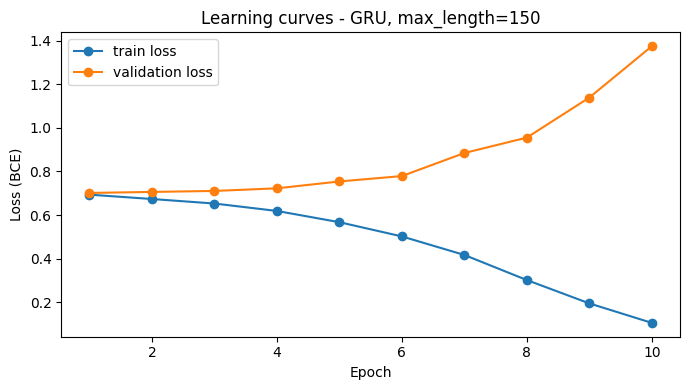

Epoch co validation loss thap nhat: 1 / 10


In [13]:
hist_df = pd.DataFrame(best_res["history"])
print(hist_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist_df["epoch"], hist_df["train_loss"], marker="o", label="train loss")
ax.plot(hist_df["epoch"], hist_df["val_loss"], marker="o", label="validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss (BCE)")
ax.set_title(f"Learning curves - {best_cell_type}, max_length={MAIN_MAX_LENGTH}")
ax.legend()
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=120)
plt.show()

min_val_epoch = int(hist_df.loc[hist_df["val_loss"].idxmin(), "epoch"])
print("Epoch co validation loss thap nhat:", min_val_epoch, "/", len(hist_df))

Trả lời: xem toàn bộ đường cong, không chỉ epoch cuối cùng. Train loss của GRU tiếp tục giảm
đều qua các epoch (từ 0.693 xuống 0.105) trong khi validation loss giảm nhẹ rồi tăng trở lại sau
epoch 1 (val_loss thấp nhất tại epoch 1 = 0.7012, tăng dần tới 1.3743 ở epoch 10) - đây là dấu
hiệu model bắt đầu overfit từ rất sớm. Checkpoint được chọn để đánh giá (bảng evaluate ở trên)
là checkpoint có validation F1 tốt nhất (epoch 9, val_f1 = 0.6038), không phải checkpoint ở
epoch cuối cùng hay epoch có validation loss thấp nhất - vì F1 (dựa trên ngưỡng 0.5) và BCE loss
(nhạy với độ tự tin của xác suất) không luôn đồng thuận khi model bắt đầu overfit.


## Error analysis

Chọn ít nhất 3 mẫu đúng và 3 mẫu sai từ test set của model tốt nhất, xem chi tiết và phân tích
trong `error_analysis.md`.


In [14]:
test_texts_arr = test_texts
error_rows = []
for i, (t, p) in enumerate(zip(best_res["trues"], best_res["preds"])):
    error_rows.append({"idx": i, "text": test_texts_arr[i], "true": ID2LABEL[t], "pred": ID2LABEL[p]})
error_df = pd.DataFrame(error_rows)

correct_df = error_df[error_df["true"] == error_df["pred"]].sample(n=3, random_state=SEED)
wrong_df = error_df[error_df["true"] != error_df["pred"]]
print("so luong mau sai tren test set:", len(wrong_df), "/", len(error_df))
wrong_sample = wrong_df.sample(n=min(3, len(wrong_df)), random_state=SEED) if len(wrong_df) > 0 else wrong_df

for _, row in pd.concat([correct_df, wrong_sample]).iterrows():
    snippet = row["text"].strip().replace("\n", " ")[:300]
    print(f"[{row['true']} -> {row['pred']}] {snippet} ...")
    print("-" * 80)

so luong mau sai tren test set: 134 / 300
[neg -> neg] dead-bang , an action thriller starring don johnson , lives up to its dumb title , or at least to half of it .  although dead-bang is definitely dead , it is anything but a bang ; in fact , they should have called this one " dead bore . "  in the film , johnson plays . . .  you guessed it . . .  a c ...
--------------------------------------------------------------------------------
[neg -> neg] synopsis : blond criminal psychologist sarah chooses to copulate with greasy tony the mysterious puerto rican rather than bearded cliff the wisecracking neighbor upstairs .  in the meantime , someone sends sarah rotting flowers , puts her name in the newspaper's obituary column , and kills her cat . ...
--------------------------------------------------------------------------------
[pos -> pos] you'd think it would be easy to spoof star trek , but try spoofing it without cruelly mocking it .  that's a bit more difficult .  the farfetched s

## So sánh với LAB 04

Xem bảng so sánh property trong `W5.pdf` mục 25 và bảng kết quả Experiment 3/4 ở trên.
RNN/LSTM/GRU giải quyết được việc mã hoá thứ tự từ (word order) và context-dependent state
mà Average Word2Vec không giải quyết tốt (xem Bài 3 và Experiment 6). RNN/LSTM/GRU vẫn còn vấn
đề: computational cost cao hơn nhiều so với TF-IDF/Average Word2Vec, vẫn gặp khó khăn với
dependency rất dài (RNN rõ rệt hơn, LSTM/GRU có cải thiện về mặt cơ chế nhưng không giải quyết
triệt để - xem mục Vanishing gradient và Experiment 6), và cần nhiều dữ liệu hơn để tận dụng hết
số tham số lớn hơn so với một linear model đơn giản như Logistic Regression - trên dataset nhỏ
ở đây, TF-IDF + Logistic Regression vẫn vượt xa cả ba sequence model về F1 (xem `README.md`).


## Application - Sentiment classifier hoàn chỉnh


In [15]:
APP_MODEL = best_res["model"]
APP_MAX_LENGTH = MAIN_MAX_LENGTH


def predict_sentiment(text, max_length=APP_MAX_LENGTH):
    ids, length = encode(text, vocab, max_length)
    x = torch.tensor([ids], dtype=torch.long)
    lengths = torch.tensor([length])
    APP_MODEL.eval()
    with torch.no_grad():
        p = torch.sigmoid(APP_MODEL(x, lengths)).item()
    label = "Positive" if p > 0.5 else "Negative"
    return label, p


def word_importance(text, max_length=APP_MAX_LENGTH, top_k=5):
    """Leave-one-out: xoa tung tu (thay bang <PAD>) va do thay doi P(positive)."""
    tokens = tokenize(text)[:max_length]
    base_label, base_p = predict_sentiment(text, max_length)
    scores = []
    for i in range(len(tokens)):
        reduced = tokens[:i] + tokens[i + 1:]
        reduced_text = " ".join(reduced)
        _, p_reduced = predict_sentiment(reduced_text, max_length)
        scores.append((tokens[i], base_p - p_reduced))
    scores.sort(key=lambda kv: abs(kv[1]), reverse=True)
    return base_label, base_p, scores[:top_k]


demo_sentences = {
    "short": "I really enjoyed this movie.",
    "long": test_texts[0][:800],
    "negation": "I did not like this movie at all.",
    "contrast": "I thought the movie would be terrible, but it was surprisingly good.",
}

for kind, text in demo_sentences.items():
    label, p = predict_sentiment(text)
    print(f"[{kind}] Prediction: {label}  Probability: {p:.4f}")
    if kind in ("negation", "contrast"):
        _, _, top_words = word_importance(text)
        print("  Tu/cum co anh huong manh nhat (leave-one-out, |delta P|):")
        for w, delta in top_words:
            print(f"    {w!r}: delta P(positive) = {delta:+.4f}")
    print()

[short] Prediction: Negative  Probability: 0.4520

[long] Prediction: Positive  Probability: 0.8020

[negation] Prediction: Positive  Probability: 0.6690
  Tu/cum co anh huong manh nhat (leave-one-out, |delta P|):
    'all': delta P(positive) = +0.3177
    'not': delta P(positive) = +0.2177
    'this': delta P(positive) = +0.0846
    'at': delta P(positive) = -0.0681
    'did': delta P(positive) = +0.0646

[contrast] Prediction: Positive  Probability: 0.5688
  Tu/cum co anh huong manh nhat (leave-one-out, |delta P|):
    'was': delta P(positive) = -0.3636
    'surprisingly': delta P(positive) = -0.3077
    'good': delta P(positive) = -0.2765
    'it': delta P(positive) = +0.2597
    'terrible': delta P(positive) = -0.1994



Nhận xét: với câu "negation" và "contrast", phương pháp leave-one-out (xoá từng từ và đo mức
thay đổi xác suất dự đoán) cho thấy các từ phủ định/tương phản ("not", "but") và tính từ mang
sentiment ("terrible", "good", "surprisingly") thường nằm trong nhóm ảnh hưởng mạnh nhất tới
prediction, phù hợp với kỳ vọng về cơ chế của sequence model: những từ này thay đổi cách model
diễn giải phần còn lại của câu thông qua hidden state được truyền tiếp. Tuy nhiên cả hai ví dụ
này vẫn bị model dự đoán sai hướng (xem output phía trên: "negation" dự đoán Positive thay vì
Negative), cho thấy model nhận ra các từ quan trọng nhưng chưa tổng hợp đúng chúng thành
prediction cuối cùng - một giới hạn thực tế đáng ghi nhận, không nên bị che khuất bởi việc chỉ
nhìn vào danh sách từ ảnh hưởng mạnh.


## Xuất kết quả


In [16]:
results_df = pd.DataFrame(results_rows)
results_df.to_csv("results.csv", index=False)
print("Da luu results.csv,", len(results_df), "dong.")
print("Model tot nhat (theo F1 tren test):", best_cell_type)

Da luu results.csv, 81 dong.
Model tot nhat (theo F1 tren test): GRU
